In [18]:
import torch
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, root_mean_squared_error, mean_squared_error
from torch import Tensor
from torch.nn import Sequential, Linear, ReLU, MSELoss, Module
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [19]:
class MyDataset(Dataset):
    def __init__(self, datas: np.ndarray, labels: np.ndarray) -> None:
        self._x = torch.from_numpy(datas).float()
        self._y = torch.from_numpy(labels).float()

    def __len__(self) -> int:
        return len(self._x)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        int(idx)
        return self._x[idx], self._y[idx]

In [20]:
class CustomModel(Module):
    def __init__(self, input_size: int, output_size) -> None:
        super().__init__()
        self.net = Sequential(
            Linear(input_size, 32),
            ReLU(),
            Linear(32,16),
            ReLU(),
            Linear(16, output_size)
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.net(x)

In [21]:
def train_model_reg(features, targets, kf, batch, epochs, criterion, exp=False):
    r2_scores = []
    mse_scores = []
    rmse_scores = []
    folds_loss = []
    r2_loss = []

    for i, (train_index, test_index) in enumerate(kf.split(features)):
        print(f"Treinando modelo ----- Fold {i + 1}")
        train_data = MyDataset(features[train_index], targets[train_index])
        train_loader = DataLoader(train_data, batch_size=batch)
        model = CustomModel(10, 1)
        optmizer = Adam(model.parameters(), lr=0.001)
        epoch_loss = []
        epoch_r2 = []
        
        for i_epochs in range(epochs):    
            batches_loss = []
            all_preds = []
            all_targets = []
            model.train()
            
            for x, y in train_loader:
                optmizer.zero_grad()
                output = model(x)
                loss = criterion(output, y)
                loss.backward()
                batches_loss.append(loss.item())
                optmizer.step()

                batches_loss.append(loss.item())
                all_preds.append(output.detach().numpy())
                all_targets.append(y.numpy())

            epoch_loss.append(np.mean(batches_loss))
            y_true_epoch = np.vstack(all_targets)
            y_pred_epoch = np.vstack(all_preds)
            epoch_r2.append(r2_score(y_true_epoch, y_pred_epoch))

        folds_loss.append(epoch_loss)
        r2_loss.append(epoch_r2)
        
        model.eval()
        with torch.no_grad():
            x_test_tensor = Tensor(features[test_index]).float()
            y_true = targets[test_index]
            result = model(x_test_tensor).cpu().numpy()
            r2_s = r2_score(y_true, result)
            rmse_s = root_mean_squared_error(y_true, result)
            mse_s = mean_squared_error(y_true, result)
            r2_scores.append(r2_s)
            rmse_scores.append(rmse_s)
            mse_scores.append(mse_s)
            print(f"R^2: {r2_s}")
            print(f"RMSE: {rmse_s}")
            print(f"MSE: {mse_s}")

        if exp:
            break

    print(f"\nResultado modelo ----- R^2: {np.mean(r2_scores)}, RMSE: {np.mean(rmse_scores)}, MSE: {np.mean(mse_scores)}")

    return folds_loss, r2_loss

In [22]:
def plot_loss(folds_loss, r2_loss):
    for idx, fold_l in enumerate(folds_loss):
        fig, ax1 = plt.subplots(figsize=(7, 3))
        x = np.linspace(0, len(fold_l), len(fold_l))

        ax1.plot(x, fold_l, color="red", label="Erro")
        ax1.set_xlabel("Épocas")
        ax1.set_ylabel("Erro")
        ax1.set_ylim(0, np.max(fold_l) * 1.1)
        
        ax2 = ax1.twinx()
        ax2.plot(x, r2_loss[idx], color="blue", label="r2")
        ax2.set_ylabel("r2")
        ax2.set_ylim(-1,1)
        ax2.grid(True)

        fig.legend(loc="upper right")
        fig.show()


In [23]:
dataset = load_diabetes()
features = dataset.data
targets = np.expand_dims(dataset.target, axis=1)
scaler = StandardScaler()
features = scaler.fit_transform(features)

In [24]:
criterion = MSELoss()
max_epochs = 200
batch = 8
kf = KFold(n_splits=5, shuffle=True)

In [25]:
folds_loss, r2_loss = train_model_reg(features, targets, kf, batch, max_epochs, criterion, True)

Treinando modelo ----- Fold 1
R^2: 0.4787503224528886
RMSE: 56.24288579608201
MSE: 3163.2622026711233

Resultado modelo ----- R^2: 0.4787503224528886, RMSE: 56.24288579608201, MSE: 3163.2622026711233


C:\Users\Aluno\AppData\Local\Temp\ipykernel_49252\4175162892.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


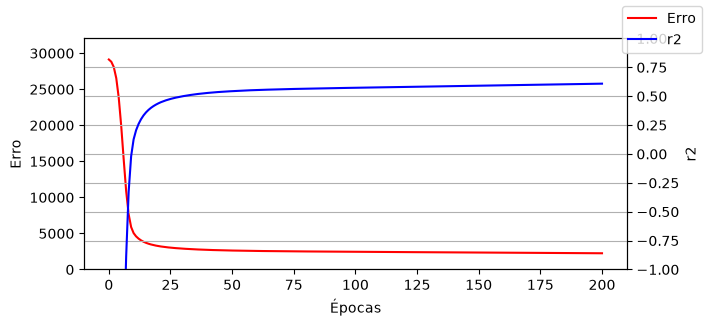

In [26]:
plot_loss(folds_loss, r2_loss)